[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Shreyashgol/phonetic-guided-speech-generation/blob/main/notebooks/10_mel_extraction_and_contract.ipynb)

# 10 · Phase 2 data: mel spectrograms and the Phase 1 → Phase 2 contract
**Goal:** turn the Phase 1 outputs into training data for the acoustic model (phonemes + durations → mel).

**Design decisions (put these in the report)**
- **Mel recipe is the vocoder's recipe.** The pretrained HiFi-GAN (22.05 kHz) expects: reflect-pad `(n_fft-hop)/2` on both sides, STFT with `center=False`, magnitude, Slaney mel filters, natural log with a floor of 1e-5. If our mels differ, the vocoder produces noise. Frames per clip = `samples // hop`.
- **Token sequence keeps silence.** Every row of the alignment (speech phones *and* `sil`) is a token, so durations sum exactly to the mel length. Inputs also get a stress id (0 none, 1/2/3 for stress 0/1/2).
- **Durations sum to mel frames.** Alignment rounding and the Phase 1 clip-to-1 rule can change the total by a frame or two. We fix that by adding the difference to the longest token and **record how big the fix was**.
- **Same splits as Phase 1.** We read the frozen `train/val/test_ids.txt`. Utterances excluded by QA stay excluded. Utterances containing `spn` are dropped (unknown words have no usable phones).
- **Normalisation statistics come from train only.** Mean/std per mel bin; no test leakage.
- **Silence at inference.** Phase 1 never predicted `sil`. We save median silence lengths (leading / internal / trailing) to use at inference time.

**Reads:** wavs, `phone_durations.csv.gz`, `alignment_qa.csv`, split files. **Writes:** `data/processed/mels/*.npy`, `phase2_manifest.csv`, `mel_stats.json`, `sil_stats.json`, `phase2_contract.json`.

In [ ]:
# ---- Cell 0: Setup (identical at the top of every notebook)
import os, sys, json, glob
try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_ROOT = '/content/drive/MyDrive/phonetic-tts'
    IN_COLAB = True
except ImportError:                      # running somewhere else (local / tests)
    PROJECT_ROOT = os.environ.get('PROJECT_ROOT', os.getcwd())
    IN_COLAB = False
sys.path.insert(0, PROJECT_ROOT)
from src.utils.config import load_config
cfg = load_config(PROJECT_ROOT)
A = cfg['audio']; P = cfg['abs_paths']
RAW, PROCESSED, ALIGN, SPLITS, RESULTS = P['raw'], P['processed'], P['alignments'], P['splits'], P['results']
for d in (PROCESSED, ALIGN, SPLITS, RESULTS):
    os.makedirs(d, exist_ok=True)
print('Project root:', PROJECT_ROOT, '| Colab:', IN_COLAB)

Mounted at /content/drive
Project root: /content/drive/MyDrive/phonetic-tts | Colab: True


In [ ]:
# ---- Write shared module: phoneme inventory
import os, importlib
_src = r'''"""Shared phoneme inventory (ARPAbet, as used by MFA english_us_arpa). Used by Phase 1 and Phase 2."""
import re

VOWELS = ['AA', 'AE', 'AH', 'AO', 'AW', 'AY', 'EH', 'ER', 'EY', 'IH', 'IY', 'OW', 'OY', 'UH', 'UW']
DIPHTHONGS = ['AW', 'AY', 'EY', 'OW', 'OY']
CONSONANT_CLASS = {
    'stop': ['B', 'D', 'G', 'K', 'P', 'T'],
    'affricate': ['CH', 'JH'],
    'fricative': ['DH', 'F', 'HH', 'S', 'SH', 'TH', 'V', 'Z', 'ZH'],
    'nasal': ['M', 'N', 'NG'],
    'liquid': ['L', 'R'],
    'glide': ['W', 'Y'],
}
SPECIAL = ['sil', 'spn']          # silence, unknown-word noise
PAD = '<pad>'

BASE_PHONES = VOWELS + [p for v in CONSONANT_CLASS.values() for p in v]
PHONE_LIST = [PAD] + sorted(BASE_PHONES) + SPECIAL
PHONE2ID = {p: i for i, p in enumerate(PHONE_LIST)}

_CLASS = {p: 'vowel' for p in VOWELS}
for _c, _ps in CONSONANT_CLASS.items():
    for _p in _ps:
        _CLASS[_p] = _c
_CLASS['sil'] = 'sil'
_CLASS['spn'] = 'spn'
CLASS_LIST = ['vowel', 'stop', 'affricate', 'fricative', 'nasal', 'liquid', 'glide', 'sil', 'spn']
CLASS2ID = {c: i for i, c in enumerate(CLASS_LIST)}


def split_stress(label):
    """'AH0' -> ('AH', 0); 'T' -> ('T', -1); '' -> ('sil', -1); 'spn' -> ('spn', -1)."""
    if label == '' or label is None:
        return 'sil', -1
    if label.lower() in ('sil', 'sp'):
        return 'sil', -1
    if label.lower() == 'spn':
        return 'spn', -1
    m = re.match(r'^([A-Z]+?)([012])?$', label)
    if not m:
        return label, -1
    return m.group(1), (int(m.group(2)) if m.group(2) is not None else -1)


def phone_class(base):
    return _CLASS.get(base, 'unknown')
'''
_p = os.path.join(PROJECT_ROOT, "src/features/phones.py")
os.makedirs(os.path.dirname(_p), exist_ok=True)
for _d in ["src", os.path.dirname("src/features/phones.py")]:
    open(os.path.join(PROJECT_ROOT, _d, "__init__.py"), "a").close()
open(_p, "w").write(_src)
importlib.invalidate_caches()
print("wrote", _p)

wrote /content/drive/MyDrive/phonetic-tts/src/features/phones.py


## Step 1: Mel function (matches the HiFi-GAN recipe)

In [ ]:
import numpy as np, pandas as pd, soundfile as sf, librosa, scipy.signal
SR, NFFT, HOP, WIN = A['sample_rate'], A['n_fft'], A['hop_length'], A['win_length']
NMEL, FMIN, FMAX = A['n_mels'], A['f_min'], A['f_max']
MEL_BASIS = librosa.filters.mel(sr=SR, n_fft=NFFT, n_mels=NMEL, fmin=FMIN, fmax=FMAX)   # Slaney (librosa default)
WINDOW = scipy.signal.get_window('hann', WIN, fftbins=True)                             # periodic Hann = torch.hann_window

def wav_to_mel(path):
    y, sr = sf.read(path, dtype='float32')
    assert sr == SR, f'{path}: sample rate {sr}'
    if y.ndim > 1: y = y.mean(1)
    pad = (NFFT - HOP) // 2
    y = np.pad(y, (pad, pad), mode='reflect')
    S = librosa.stft(y, n_fft=NFFT, hop_length=HOP, win_length=WIN, window=WINDOW, center=False)
    mag = np.sqrt(S.real ** 2 + S.imag ** 2 + 1e-9)
    return np.log(np.clip(MEL_BASIS @ mag, 1e-5, None)).T.astype(np.float32)             # (frames, n_mels)

print('mel basis', MEL_BASIS.shape, '| window', WINDOW.shape)

mel basis (80, 513) | window (1024,)


## Step 2: Which utterances are used

In [ ]:
al = pd.read_csv(os.path.join(ALIGN, 'phone_durations.csv.gz'))
qa = pd.read_csv(os.path.join(ALIGN, 'alignment_qa.csv'))
split_of = {}
for k in ('train', 'val', 'test'):
    for u in open(os.path.join(SPLITS, f'{k}_ids.txt')).read().split(): split_of[u] = k
keep = set(qa.loc[~qa.exclude, 'utt_id'])
has_spn = set(al.loc[al.base == 'spn', 'utt_id'])
use = sorted(u for u in keep if u in split_of and u not in has_spn)
print(f'aligned {al.utt_id.nunique()} | QA-kept {len(keep)} | with spn dropped {len(keep & has_spn)} | used {len(use)}')
al = al[al.utt_id.isin(set(use))].sort_values(['utt_id', 'phone_idx']).reset_index(drop=True)

aligned 13100 | QA-kept 11416 | with spn dropped 0 | used 11416


## Step 3: Extract mels (resumable: existing files are skipped)

In [ ]:
import os

# Download and extract the LJSpeech dataset
if not os.path.exists('/content/LJSpeech-1.1'):
    print("Downloading LJSpeech-1.1 dataset...")
    !wget -q --show-progress https://data.keithito.com/data/speech/LJSpeech-1.1.tar.bz2
    print("Extracting dataset...")
    !tar -xf LJSpeech-1.1.tar.bz2 -C /content/
    !rm LJSpeech-1.1.tar.bz2
    print("Extraction complete!")
else:
    print("LJSpeech-1.1 dataset already exists in /content/")

LJSpeech-1.1.tar.bz 100%[===================>]   2.56G   111MB/s    in 27s     
Extracting dataset...
Extraction complete!


In [ ]:
from tqdm.auto import tqdm
MEL_DIR = os.path.join(PROCESSED, 'mels'); os.makedirs(MEL_DIR, exist_ok=True)
n_new = 0
for u in tqdm(use):
    out = os.path.join(MEL_DIR, u + '.npy')
    if os.path.exists(out): continue
    np.save(out, wav_to_mel(os.path.join(RAW, 'wavs', u + '.wav')).astype(np.float16)); n_new += 1
print('new mels:', n_new, '| total:', len(os.listdir(MEL_DIR)))

  0%|          | 0/11416 [00:00<?, ?it/s]

new mels: 11416 | total: 11416


## Step 4: Build the token + duration table and make durations sum to the mel length
`stress` ids: 0 = none, 1 = stress 0, 2 = stress 1, 3 = stress 2.

In [ ]:
from src.features.phones import PHONE2ID
VOCAB = {'<pad>': 0, **{p: i + 1 for i, p in enumerate(sorted(set(al.base)))}}
assert set(al.base) <= set(VOCAB), set(al.base) - set(VOCAB)
al['stress_id'] = al['stress'].fillna(-1).astype(int).map({-1: 0, 0: 1, 1: 2, 2: 3})
al['tok'] = al['base'].map(VOCAB)
rows, fixes, bad = [], [], []
for u, g in al.groupby('utt_id', sort=False):
    n_mel = np.load(os.path.join(MEL_DIR, u + '.npy'), mmap_mode='r').shape[0]
    d = g['dur_f'].clip(lower=0).to_numpy().astype(int)
    keep_tok = d > 0                                   # a 0-frame token cannot be expanded
    toks, strs, d, bases = g['tok'].to_numpy()[keep_tok], g['stress_id'].to_numpy()[keep_tok], d[keep_tok], g['base'].to_numpy()[keep_tok]
    diff = n_mel - d.sum()
    if diff != 0:
        j = int(np.argmax(d)); d[j] += diff            # absorb in the longest token
    fixes.append(int(diff))
    if abs(diff) > 3 or d.min() < 1: bad.append(u); continue
    assert d.sum() == n_mel
    rows.append(dict(utt_id=u, split=split_of[u], n_frames=n_mel, n_tokens=len(d),
                     tokens=' '.join(map(str, toks)), stress=' '.join(map(str, strs)), durations=' '.join(map(str, d)),
                     bases=' '.join(bases)))
man = pd.DataFrame(rows)
fx = np.array(fixes)
print(f'utterances: {len(man)} | dropped (|fix|>3): {len(bad)}')
print(f'duration-sum fix: exactly 0 -> {(fx==0).mean():.1%} | |fix|<=1 -> {(abs(fx)<=1).mean():.1%} | max |fix| = {abs(fx).max()}')
man.to_csv(os.path.join(PROCESSED, 'phase2_manifest.csv'), index=False)
man.split.value_counts()

utterances: 11416 | dropped (|fix|>3): 0
duration-sum fix: exactly 0 -> 0.0% | |fix|<=1 -> 100.0% | max |fix| = 1


,count
split,
train,10283
val,581
test,552


## Step 5: Silence statistics (for inference) and normalisation statistics (train only)

In [ ]:
import json
a = al[al.utt_id.isin(set(man.utt_id))].copy()
a['is_last'] = a.phone_idx == a.groupby('utt_id').phone_idx.transform('max')
a['is_first'] = a.phone_idx == a.groupby('utt_id').phone_idx.transform('min')
s = a[a.base == 'sil']; mid = s[~s.is_first & ~s.is_last].dur_f
sil_stats = {'leading': float(s[s.is_first].dur_f.median()),
             'trailing': float(s[s.is_last].dur_f.median()),
             'internal': float(mid.median()),
             'internal_p25_p75': [float(mid.quantile(q)) for q in (.25, .75)]}
print('median silence frames:', sil_stats)
json.dump(sil_stats, open(os.path.join(PROCESSED, 'sil_stats.json'), 'w'), indent=1)

tr_ids = man.loc[man.split == 'train', 'utt_id']
tot = np.zeros(NMEL); tot2 = np.zeros(NMEL); cnt = 0
for u in tqdm(tr_ids):
    m = np.load(os.path.join(MEL_DIR, u + '.npy')).astype(np.float64)
    tot += m.sum(0); tot2 += (m ** 2).sum(0); cnt += len(m)
mean = tot / cnt; std = np.sqrt(tot2 / cnt - mean ** 2)
json.dump({'mean': mean.tolist(), 'std': std.tolist(), 'frames': int(cnt)}, open(os.path.join(PROCESSED, 'mel_stats.json'), 'w'))
print('train frames:', cnt, '| mean range', mean.min().round(2), mean.max().round(2), '| std range', std.min().round(2), std.max().round(2))

median silence frames: {'leading': 3.0, 'trailing': 8.0, 'internal': 15.0, 'internal_p25_p75': [4.0, 28.0]}


  0%|          | 0/10283 [00:00<?, ?it/s]

train frames: 5761048 | mean range -7.36 -3.57 | std range 0.77 2.18


## Step 6: Write the contract file and run sanity checks

In [ ]:
contract = {'audio': A, 'mel_recipe': 'hifigan: reflect pad (n_fft-hop)/2, center=False, magnitude, slaney mel, ln clip 1e-5',
            'vocab': VOCAB, 'stress_ids': {'none': 0, 'stress0': 1, 'stress1': 2, 'stress2': 3},
            'n_utts': {k: int(v) for k, v in man.split.value_counts().items()},
            'duration_unit': 'mel frames (hop=%d @ %d Hz = %.2f ms)' % (HOP, SR, 1000 * HOP / SR),
            'split_files': 'data/splits/{train,val,test}_ids.txt (frozen in notebook 05)'}
json.dump(contract, open(os.path.join(PROCESSED, 'phase2_contract.json'), 'w'), indent=1)

# 1) every utterance in manifest: durations sum to frames, tokens in vocab
for r in man.itertuples():
    d = np.array(r.durations.split(), int); assert d.sum() == r.n_frames and len(d) == r.n_tokens and d.min() >= 1
# 2) splits are disjoint and match Phase 1
assert not (set(man[man.split=='train'].utt_id) & set(man[man.split=='test'].utt_id))
# 3) frame length vs seconds
print('mean seconds per clip:', (man.n_frames * HOP / SR).mean().round(2), '| tokens per clip:', man.n_tokens.mean().round(1))
print('ALL CHECKS PASSED | vocab size (incl. pad):', len(VOCAB))

mean seconds per clip: 6.5 | tokens per clip: 71.9
ALL CHECKS PASSED | vocab size (incl. pad): 41


## Step 7: Look at one example (mel with phone boundaries)

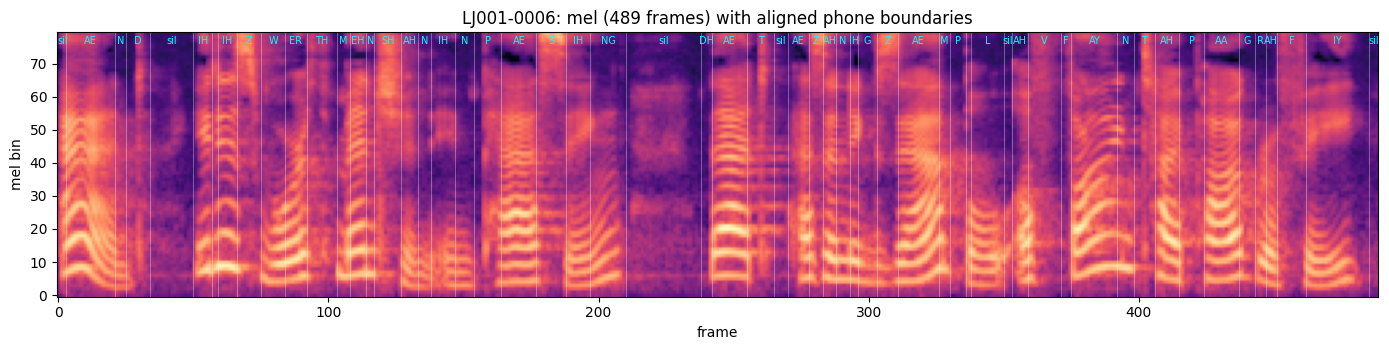

In [ ]:
import matplotlib.pyplot as plt
r = man[man.split == 'val'].iloc[0] if (man.split == 'val').any() else man.iloc[0]
m = np.load(os.path.join(MEL_DIR, r.utt_id + '.npy')).astype(np.float32)
d = np.array(r.durations.split(), int); b = r.bases.split(); edges = np.cumsum(d)
fig, ax = plt.subplots(figsize=(14, 3.6))
ax.imshow(m.T, origin='lower', aspect='auto', cmap='magma')
for e in edges[:-1]: ax.axvline(e, color='w', lw=.4, alpha=.6)
for s0, dd, bb in zip(edges - d, d, b):
    if dd >= 3: ax.text(s0 + dd / 2, NMEL - 4, bb, color='cyan', ha='center', fontsize=7)
ax.set_title(f'{r.utt_id}: mel ({m.shape[0]} frames) with aligned phone boundaries'); ax.set_xlabel('frame'); ax.set_ylabel('mel bin')
fig.tight_layout(); fig.savefig(os.path.join(RESULTS, '10_mel_alignment_example.png'), dpi=130); plt.show()

## What to check before moving on
1. `ALL CHECKS PASSED` printed, and the duration-sum fix is **0 or ±1 for almost all utterances** (if large, tell the group: alignment and audio disagree).
2. In the plot, phone boundaries should line up with visible changes in the mel (vowel formant bands, silences as dark gaps). If they are shifted, stop and check `hop_length`.
3. Commit `phase2_contract.json` and `mel_stats.json` (small). Do **not** commit the mel folder (large); keep it on Drive.

**Next:** notebook 11 builds the acoustic model (FastSpeech 2-style, without pitch/energy at first).